# Cancel a running task

A long-running task is cancelled with ray.cancel. Getting its result afterwards raises TaskCancelledError.

**When to use it.** Stopping speculative work once another branch wins, or abandoning tasks when a user aborts a request.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

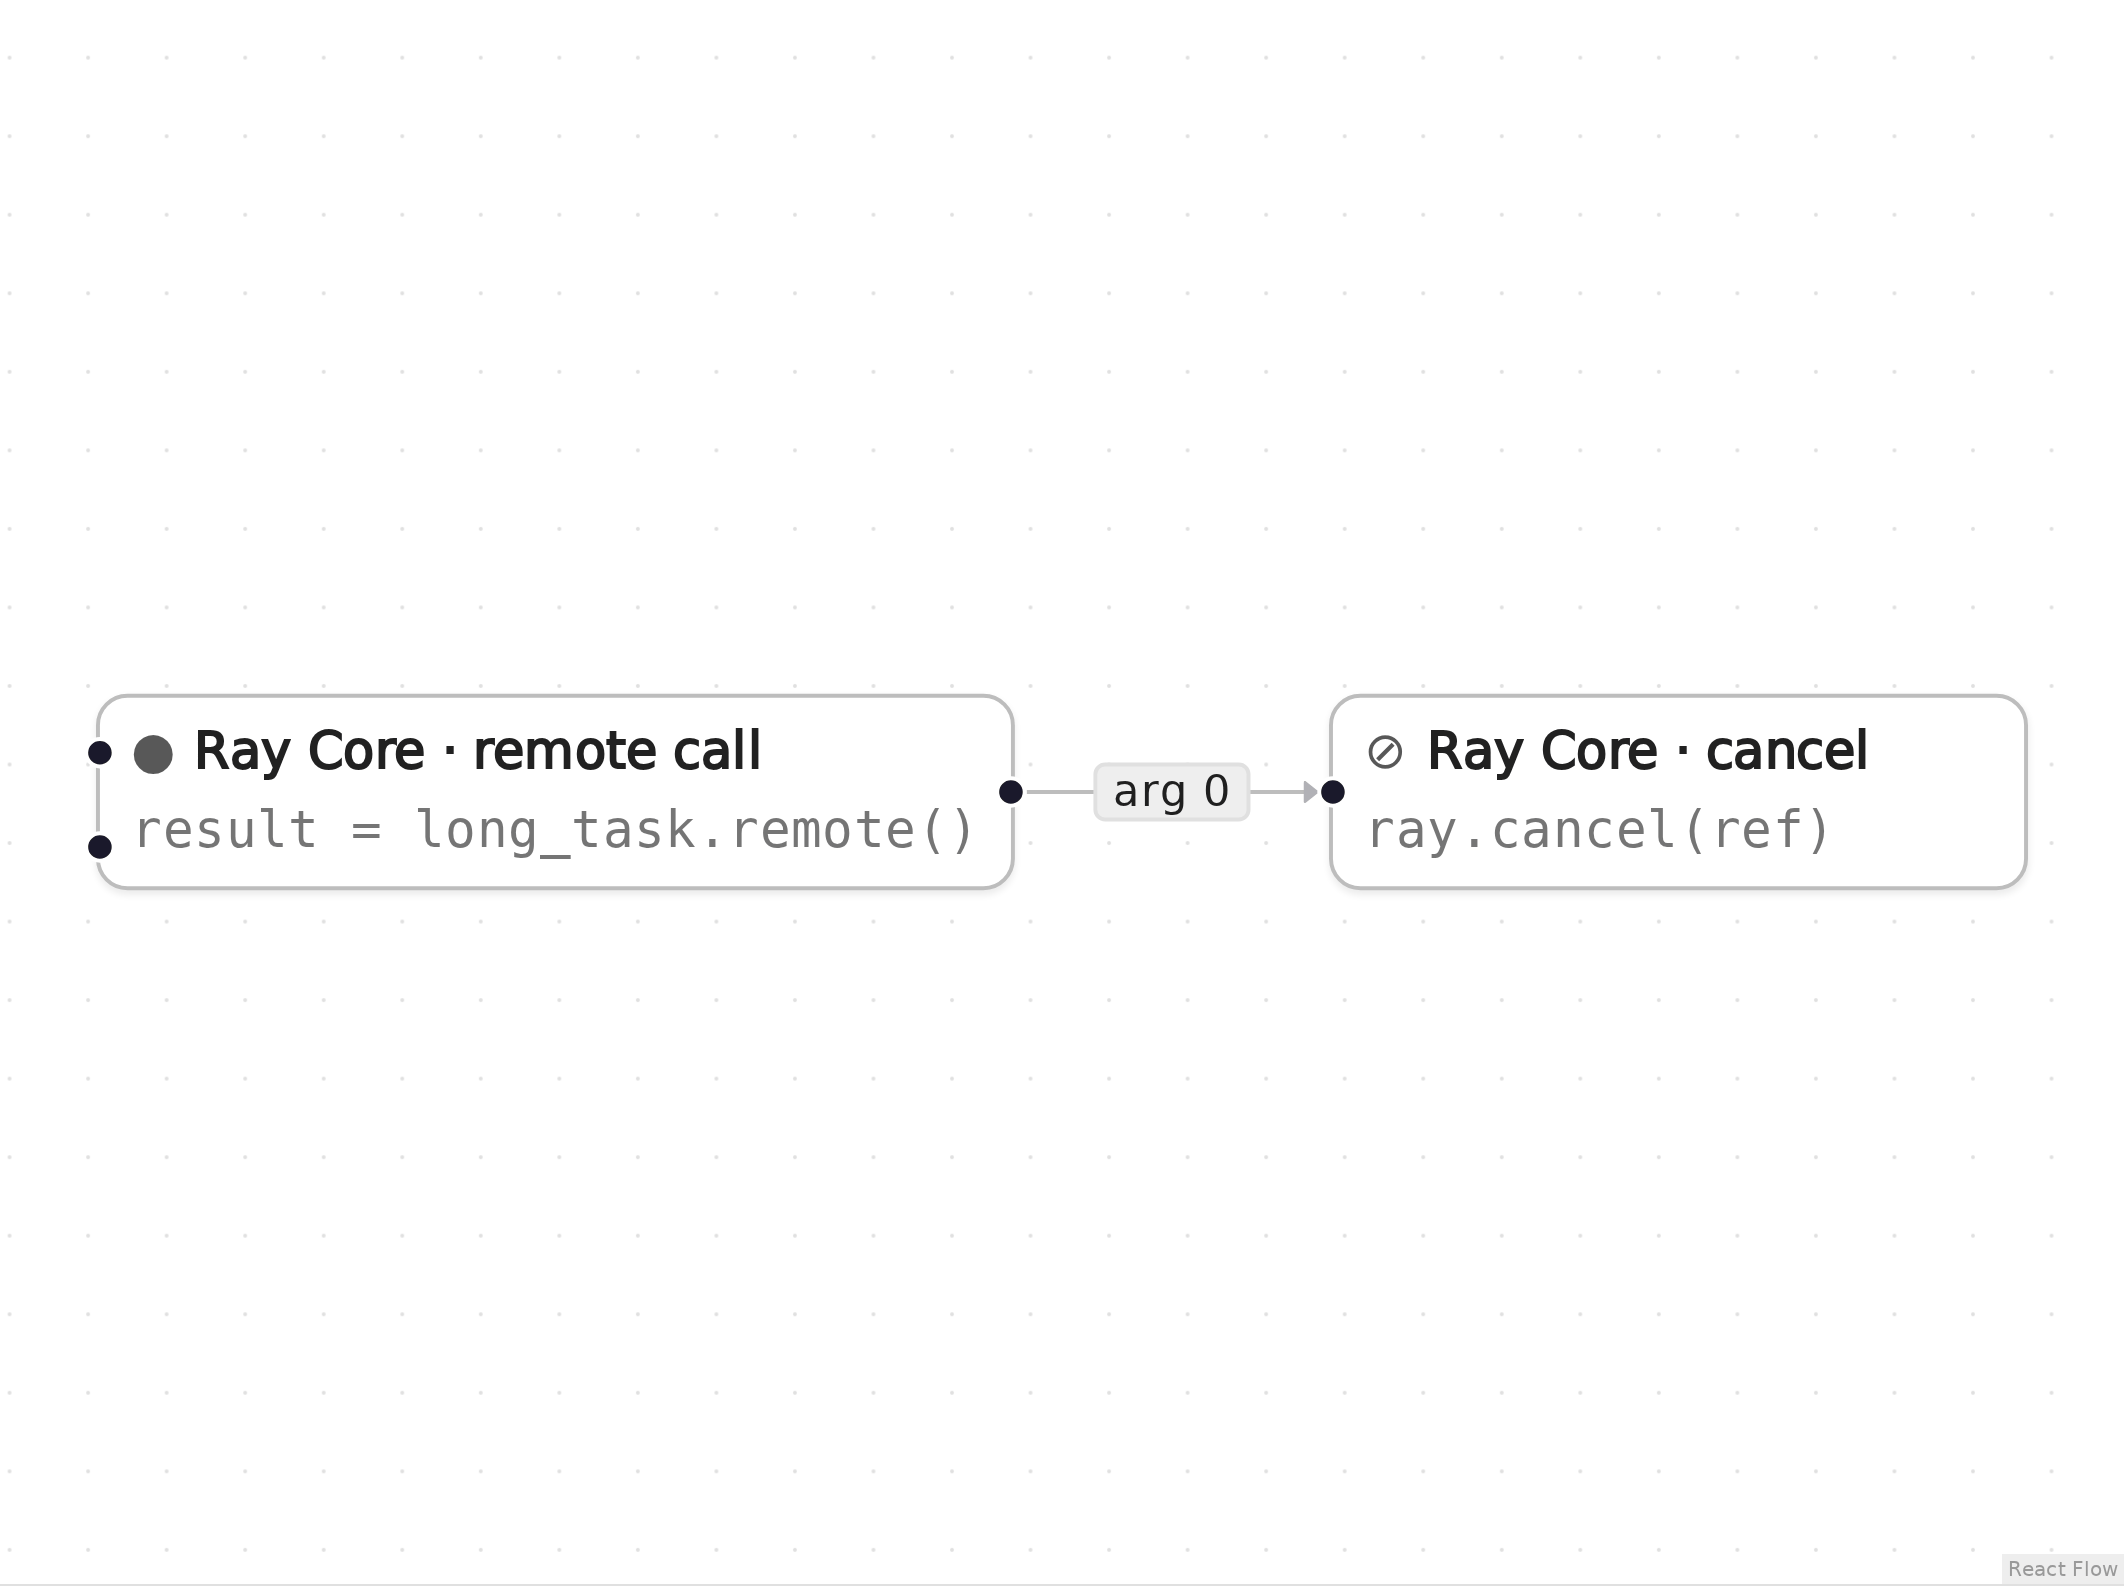

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import time


def long_task():
    time.sleep(600)
    return "finished"

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

_n1 = ray.remote(long_task).remote()
ray.cancel(_n1)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
from ray.exceptions import TaskCancelledError

try:
    ray.get(_n1, timeout=60)
except TaskCancelledError:
    print("long_task was cancelled")
else:
    raise AssertionError("expected the task to be cancelled")

long_task was cancelled


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote task** (node `n1`, line 8)

```python
_n1 = ray.remote(long_task).remote()
```

Starts a task that would sleep for ten minutes.

**Cancel** (node `c1`, line 9)

```python
ray.cancel(_n1)
```

ray.cancel interrupts it. Without force=True Ray raises KeyboardInterrupt inside the task, so cleanup code can run; force=True kills the worker process instead.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()